# Chapter 21: Project: Retail Sales Review

The programs from Chapter 21 of *Data Analysis with Python, Hands-On* by Aadhavan Muthurengan, in the book's order. Each code cell is one program; the same program is in this folder as a `.py` file, and its expected output is in the `.out` file with the same name.

Run the cells from top to bottom (**Run > Run All Cells**). The programs read the datasets from `../data/`, so keep this notebook in its chapter folder.

## Revenue, Profit and Growth by Category

`sales_review.py`

In [1]:
import pandas as pd

orders = pd.read_csv("../data/orders.csv", parse_dates=["order_date"])
products = pd.read_csv("../data/products.csv")
df = orders.merge(
    products[["product", "unit_cost"]], on="product", validate="many_to_one"
)
df["revenue"] = df["quantity"] * df["unit_price"] * (1 - df["discount"])
df["profit"] = df["revenue"] - df["quantity"] * df["unit_cost"]

print(
    f"Revenue ${df['revenue'].sum():,.0f}, "
    f"profit ${df['profit'].sum():,.0f} "
    f"({df['profit'].sum() / df['revenue'].sum():.1%} margin)"
)
print()

h1 = df["order_date"].dt.month <= 6
growth = (
    df[~h1].groupby("category")["revenue"].sum()
    / df[h1].groupby("category")["revenue"].sum()
    - 1
)
cats = df.groupby("category").agg(
    revenue=("revenue", "sum"), profit=("profit", "sum")
)
cats["margin"] = cats["profit"] / cats["revenue"]
cats["H2 vs H1"] = growth
print(
    cats.sort_values("revenue", ascending=False).round(
        {"revenue": 0, "profit": 0, "margin": 3, "H2 vs H1": 3}
    )
)

Revenue $379,703, profit $170,916 (45.0% margin)

           revenue   profit  margin  H2 vs H1
category                                     
Bedding   106166.0  47872.0   0.451     0.671
Lighting  105073.0  48944.0   0.466     0.764
Kitchen    82609.0  38081.0   0.461     0.812
Garden     48116.0  20162.0   0.419    -0.380
Decor      37739.0  15856.0   0.420     0.725


## Customers

`customers_review.py`

In [2]:
import pandas as pd

orders = pd.read_csv("../data/orders.csv", parse_dates=["order_date"])
orders["revenue"] = (
    orders["quantity"] * orders["unit_price"] * (1 - orders["discount"])
)

per_customer = orders.groupby("customer_id").agg(
    orders=("order_id", "count"), revenue=("revenue", "sum")
)
print("customers who ordered:", len(per_customer))
print(
    "ordered more than once:", (per_customer["orders"] > 1).mean().round(3)
)
print()

ranked = per_customer["revenue"].sort_values(ascending=False)
top_fifth = ranked.head(len(ranked) // 5).sum() / ranked.sum()
print(f"top 20% of customers bring {top_fifth:.0%} of revenue")
print()

first = orders.groupby("customer_id")["order_date"].transform("min")
orders["new_or_returning"] = (orders["order_date"] == first).map(
    {True: "new", False: "returning"}
)
mix = (
    orders.groupby([orders["order_date"].dt.quarter, "new_or_returning"])[
        "revenue"
    ]
    .sum()
    .unstack()
)
print((mix.div(mix.sum(axis=1), axis=0)).round(2))

customers who ordered: 1191
ordered more than once: 0.961

top 20% of customers bring 40% of revenue

new_or_returning   new  returning
order_date                       
1                 0.67       0.33
2                 0.23       0.77
3                 0.10       0.90
4                 0.02       0.98


## Do Discounts Work?

`discount_effect.py`

In [3]:
import pandas as pd

orders = pd.read_csv("../data/orders.csv")
customers = pd.read_csv("../data/customers.csv")
df = orders.merge(customers[["customer_id", "segment"]], on="customer_id")

table = df.pivot_table(
    index="discount", columns="segment", values="quantity", aggfunc="mean"
)
print("average items per order:")
print(table.round(2))
print()
print(df.groupby("discount").size().rename("orders"))

average items per order:
segment   Business  Consumer
discount                    
0.0           2.34      1.40
0.1           2.63      1.59
0.2           2.82      1.83

discount
0.0    4084
0.1    1173
0.2     576
Name: orders, dtype: int64


## One Page of Charts

`dashboard.py`

Saved dashboard.png


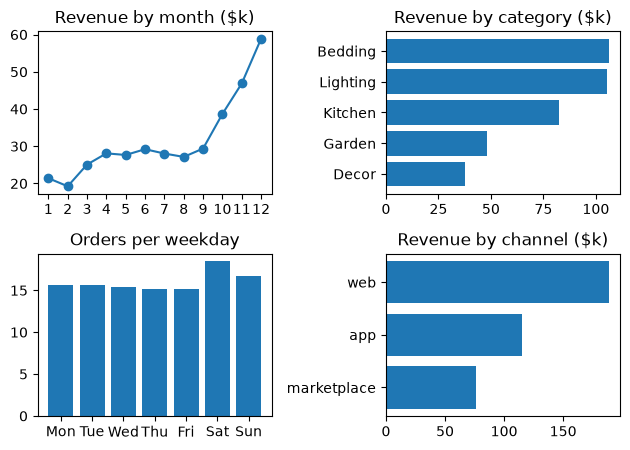

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

orders = pd.read_csv("../data/orders.csv", parse_dates=["order_date"])
orders["revenue"] = (
    orders["quantity"] * orders["unit_price"] * (1 - orders["discount"])
)
monthly = orders.set_index("order_date")["revenue"].resample("MS").sum()
by_cat = orders.groupby("category")["revenue"].sum().sort_values()
by_channel = orders.groupby("channel")["revenue"].sum().sort_values()
weekday = orders.groupby(orders["order_date"].dt.dayofweek)["order_id"]
weekday = weekday.count() / 52

fig, axes = plt.subplots(2, 2, figsize=(6.4, 4.6))
axes[0, 0].plot(monthly.index.month, monthly / 1000, marker="o")
axes[0, 0].set_title("Revenue by month ($k)")
axes[0, 0].set_xticks(range(1, 13))
axes[0, 1].barh(by_cat.index, by_cat / 1000)
axes[0, 1].set_title("Revenue by category ($k)")
axes[1, 0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], weekday)
axes[1, 0].set_title("Orders per weekday")
axes[1, 1].barh(by_channel.index, by_channel / 1000)
axes[1, 1].set_title("Revenue by channel ($k)")
fig.tight_layout()
fig.savefig("dashboard.png")
print("Saved dashboard.png")